# Employee Attrition Prediction and Workforce Retention Analysis using Machine Learning
### AI/ML-Based Real-World Application

**Group members:** _(TEITA30  Sanket Kandalkar
TEITA70    Avdhoot dhamdhere 
TEITA13   Keshav Chaudhari
TEITA07     Vijay Bhosale)
---

## 1. Problem Statement
Employee attrition (employees leaving an organisation) is expensive. Replacing one employee can cost several months of their salary once recruitment, onboarding, lost productivity and lost knowledge are counted. Most HR teams only find out *after* a resignation. A data-driven approach can warn them *before*.

**Goal:** build a machine learning system that
1. **predicts** which employees are at risk of leaving,
2. **explains** why (which factors drive attrition),
3. **segments** the workforce into risk groups, and
4. **recommends retention actions** with an estimate of the money they can save.

## 2. Objectives
1. Select a real-world HR dataset and understand it.
2. Clean, explore (EDA) and preprocess the data.
3. Engineer HR-relevant features and select the most useful ones.
4. Train and compare several ML models, handling class imbalance.
5. Tune the models with cross-validation and choose the final one **without peeking at the test set**.
6. Pick a decision threshold using a **business cost-benefit** rule instead of the default 0.5.
7. Explain predictions, score every employee into Low / Medium / High risk tiers and profile employee segments.
8. Check the model for fairness and estimate the business impact of using it.

> **Why not just accuracy?** Only about 1 in 6 employees leaves. A model that predicts "nobody leaves" would be ~84% accurate but completely useless. We therefore use **ROC-AUC, PR-AUC, recall, precision and F1**, and a business-based threshold.

## 3. Import Libraries

In [31]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.calibration import CalibratedClassifierCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay, silhouette_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
for folder in ("images", "models", "reports"):
    os.makedirs(folder, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"images/{name}.png", dpi=150, bbox_inches="tight")

## 4. Dataset Collection / Selection
**Dataset:** *IBM HR Analytics Employee Attrition & Performance* (Kaggle, `WA_Fn-UseC_-HR-Employee-Attrition.csv`).
It has **1,470 employees and 35 columns**: demographics, job role, income, satisfaction scores, overtime, travel, years at company, promotion history, and the target column **`Attrition`** (Yes/No).

**How to load it:**
1. Download it from Kaggle: <https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset>
2. Place the CSV at `data/WA_Fn-UseC_-HR-Employee-Attrition.csv`.

If the file is not found, the notebook generates a **simulated HR dataset with the same columns** so the whole pipeline can still be run and tested. **For your final submission, use the real CSV** and clearly state the dataset source in your report.

In [32]:
DATA_PATH = "data/WA_Fn-UseC_-HR-Employee-Attrition.csv"

def make_sample_hr_data(n=1470, seed=42):
    '''Simulated HR data with the same schema as the IBM dataset (used only if the real CSV is missing).'''
    rng = np.random.default_rng(seed)
    dept = rng.choice(["Research & Development", "Sales", "Human Resources"], n, p=[.65, .30, .05])
    roles = {"Research & Development": ["Research Scientist", "Laboratory Technician", "Manufacturing Director",
                                         "Healthcare Representative", "Research Director"],
             "Sales": ["Sales Executive", "Sales Representative", "Manager"],
             "Human Resources": ["Human Resources", "Manager"]}
    role = np.array([rng.choice(roles[d]) for d in dept])
    age = np.clip(rng.normal(37, 9, n).round(), 18, 60).astype(int)
    total_years = np.clip(age - 18 - rng.integers(0, 6, n), 0, 40)
    level = np.clip(1 + total_years // 8 + rng.integers(0, 2, n), 1, 5)
    income = np.clip(1500 + level * 2600 + rng.normal(0, 900, n), 1009, 19999).round().astype(int)
    overtime = rng.choice(["Yes", "No"], n, p=[.28, .72])
    travel = rng.choice(["Travel_Rarely", "Travel_Frequently", "Non-Travel"], n, p=[.71, .19, .10])
    marital = rng.choice(["Married", "Single", "Divorced"], n, p=[.46, .32, .22])
    dist = rng.integers(1, 30, n)
    ncomp = np.clip(rng.poisson(2.5, n), 0, 9)
    yrs_co = np.minimum(np.clip(rng.gamma(2.0, 3.0, n).astype(int), 0, 40), total_years)
    yrs_role = np.minimum(yrs_co, rng.gamma(1.6, 2.0, n).astype(int))
    yrs_promo = np.minimum(yrs_co, rng.gamma(1.0, 2.0, n).astype(int))
    yrs_mgr = np.minimum(yrs_co, rng.gamma(1.6, 2.0, n).astype(int))
    stock = rng.choice([0, 1, 2, 3], n, p=[.43, .40, .10, .07])
    env, job, rel, wlb, inv = [rng.choice([1, 2, 3, 4], n, p=[.2, .2, .3, .3]) for _ in range(5)]
    z = (-0.5 * 0 + 1.4 * (overtime == "Yes") + 0.8 * (marital == "Single") + 0.8 * (travel == "Travel_Frequently")
         - 0.40 * (job - 2.5) - 0.30 * (env - 2.5) - 0.30 * (wlb - 2.5) - 0.6 * (stock > 0)
         - 0.04 * (age - 37) + 0.03 * dist + 0.12 * ncomp - 0.0002 * (income - 6500)
         - 0.08 * yrs_co + 0.10 * yrs_promo)
    lo, hi = -10, 10
    for _ in range(60):                      # tune the intercept so ~16% of employees leave
        mid = (lo + hi) / 2
        if (1 / (1 + np.exp(-(z + mid)))).mean() > 0.16: hi = mid
        else: lo = mid
    p = 1 / (1 + np.exp(-(z + mid)))
    left = np.where(rng.random(n) < p, "Yes", "No")
    return pd.DataFrame({
        "Age": age, "Attrition": left, "BusinessTravel": travel,
        "DailyRate": rng.integers(100, 1500, n), "Department": dept, "DistanceFromHome": dist,
        "Education": rng.choice([1, 2, 3, 4, 5], n, p=[.12, .19, .39, .27, .03]),
        "EducationField": rng.choice(["Life Sciences", "Medical", "Marketing", "Technical Degree", "Other",
                                      "Human Resources"], n, p=[.41, .32, .11, .09, .05, .02]),
        "EmployeeCount": 1, "EmployeeNumber": np.arange(1, n + 1), "EnvironmentSatisfaction": env,
        "Gender": rng.choice(["Male", "Female"], n, p=[.6, .4]), "HourlyRate": rng.integers(30, 100, n),
        "JobInvolvement": inv, "JobLevel": level, "JobRole": role, "JobSatisfaction": job,
        "MaritalStatus": marital, "MonthlyIncome": income, "MonthlyRate": rng.integers(2000, 27000, n),
        "NumCompaniesWorked": ncomp, "Over18": "Y", "OverTime": overtime,
        "PercentSalaryHike": rng.integers(11, 26, n), "PerformanceRating": rng.choice([3, 4], n, p=[.85, .15]),
        "RelationshipSatisfaction": rel, "StandardHours": 80, "StockOptionLevel": stock,
        "TotalWorkingYears": total_years, "TrainingTimesLastYear": rng.integers(0, 7, n),
        "WorkLifeBalance": wlb, "YearsAtCompany": yrs_co, "YearsInCurrentRole": yrs_role,
        "YearsSinceLastPromotion": yrs_promo, "YearsWithCurrManager": yrs_mgr})

if os.path.exists(DATA_PATH):
    raw = pd.read_csv(DATA_PATH)
    DATA_SOURCE = "REAL: IBM HR Analytics dataset"
else:
    raw = make_sample_hr_data()
    DATA_SOURCE = "SIMULATED sample data (real CSV not found)"

print("DATA SOURCE:", DATA_SOURCE)
if DATA_SOURCE.startswith("SIMULATED"):
    print("WARNING: results below come from simulated data. Add the real CSV to data/ before submitting.")
print("Shape:", raw.shape)
raw.head()

DATA SOURCE: SIMULATED sample data (real CSV not found)
Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,30,No,Travel_Rarely,244,Sales,2,3,Other,1,1,...,1,80,0,7,5,1,3,3,0,2
1,43,No,Non-Travel,595,Research & Development,11,4,Life Sciences,1,2,...,1,80,2,20,4,1,2,0,1,1
2,30,No,Travel_Rarely,388,Sales,3,5,Life Sciences,1,3,...,3,80,1,7,0,4,3,3,3,3
3,32,No,Travel_Rarely,610,Sales,12,3,Life Sciences,1,4,...,1,80,0,10,6,4,3,3,0,2
4,29,No,Travel_Rarely,525,Research & Development,22,2,Technical Degree,1,5,...,1,80,2,9,6,4,6,3,1,6


## 5. Data Preprocessing and Exploratory Data Analysis (EDA)

### 5.1 Data quality checks

In [33]:
print("Missing values :", raw.isnull().sum().sum())
print("Duplicate rows :", raw.duplicated().sum())

# Columns with a single value carry no information; EmployeeNumber is just an ID
constant_cols = [c for c in raw.columns if raw[c].nunique() == 1]
print("Constant columns (dropped):", constant_cols)

employee_ids = raw["EmployeeNumber"].copy() if "EmployeeNumber" in raw else pd.Series(raw.index + 1)
df = raw.drop(columns=constant_cols + ["EmployeeNumber"], errors="ignore").copy()
df["Attrition"] = (df["Attrition"] == "Yes").astype(int)      # 1 = left, 0 = stayed
df.info()

Missing values : 0
Duplicate rows : 0
Constant columns (dropped): ['EmployeeCount', 'Over18', 'StandardHours']
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 31 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   int64
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EnvironmentSatisfaction   1470 non-null   int64
 9   Gender                    1470 non-null   str  
 10  HourlyRate                1470 non-null   int64
 11  JobInvolvement            1470 non-null   int64
 12  JobLevel                  1470 non-null   int6

In [34]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,37.35,8.91,18.0,31.00,37.0,44.00,60.0
Attrition,1470.0,0.16,0.37,0.0,0.00,0.0,0.00,1.0
DailyRate,1470.0,803.36,401.99,102.0,463.25,806.5,1173.75,1499.0
DistanceFromHome,1470.0,14.98,8.46,1.0,7.00,15.0,23.00,29.0
Education,1470.0,2.94,1.02,1.0,2.00,3.0,4.00,5.0
EnvironmentSatisfaction,1470.0,2.74,1.10,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,64.25,20.17,30.0,47.00,63.0,82.00,99.0
JobInvolvement,1470.0,2.70,1.11,1.0,2.00,3.0,4.00,4.0
JobLevel,1470.0,3.16,1.18,1.0,2.00,3.0,4.00,5.0
JobSatisfaction,1470.0,2.70,1.09,1.0,2.00,3.0,4.00,4.0


### 5.2 Target: how many employees leave?

Attrition rate: 15.9%   (234 left, 1236 stayed)


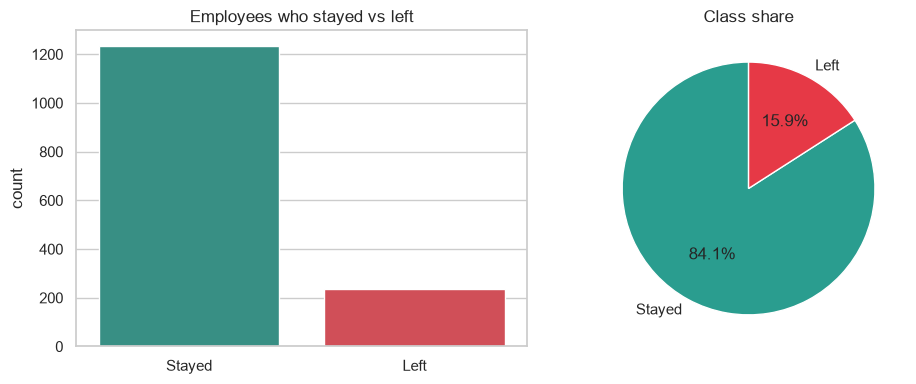

In [35]:
rate = df["Attrition"].mean()
print(f"Attrition rate: {rate:.1%}   ({df['Attrition'].sum()} left, {(1 - df['Attrition']).sum()} stayed)")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x=df["Attrition"].map({0: "Stayed", 1: "Left"}), order=["Stayed", "Left"],
              palette=["#2a9d8f", "#e63946"], ax=ax[0])
ax[0].set_title("Employees who stayed vs left"); ax[0].set_xlabel("")
ax[1].pie(df["Attrition"].value_counts().sort_index(), labels=["Stayed", "Left"], autopct="%1.1f%%",
          colors=["#2a9d8f", "#e63946"], startangle=90)
ax[1].set_title("Class share")
save_fig("01_attrition_distribution"); plt.show()

The data is **imbalanced** (the minority class is the one we care about). We will use stratified splits, class weights, and metrics that suit imbalanced problems.

### 5.3 Which groups have the highest attrition?

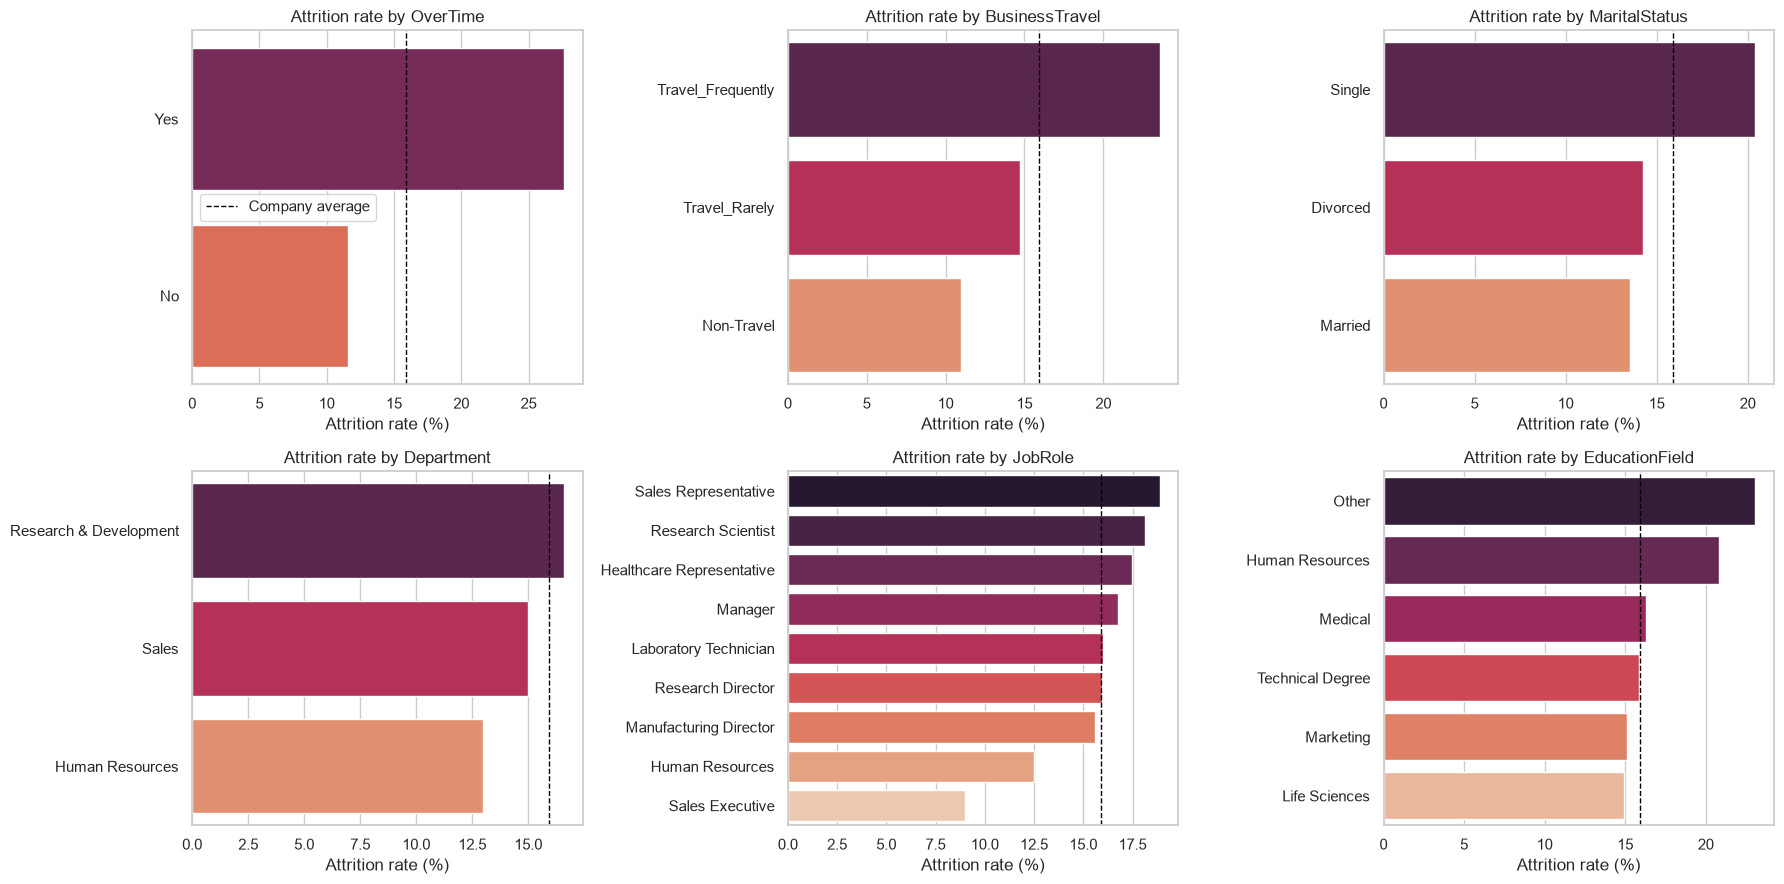

In [36]:
cat_cols_eda = ["OverTime", "BusinessTravel", "MaritalStatus", "Department", "JobRole", "EducationField"]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), cat_cols_eda):
    r = df.groupby(col)["Attrition"].mean().sort_values(ascending=False) * 100
    sns.barplot(x=r.values, y=r.index, palette="rocket", ax=ax)
    ax.axvline(rate * 100, color="black", ls="--", lw=1, label="Company average")
    ax.set_title(f"Attrition rate by {col}"); ax.set_xlabel("Attrition rate (%)"); ax.set_ylabel("")
axes[0, 0].legend()
save_fig("02_attrition_by_category"); plt.show()

### 5.4 Numeric drivers

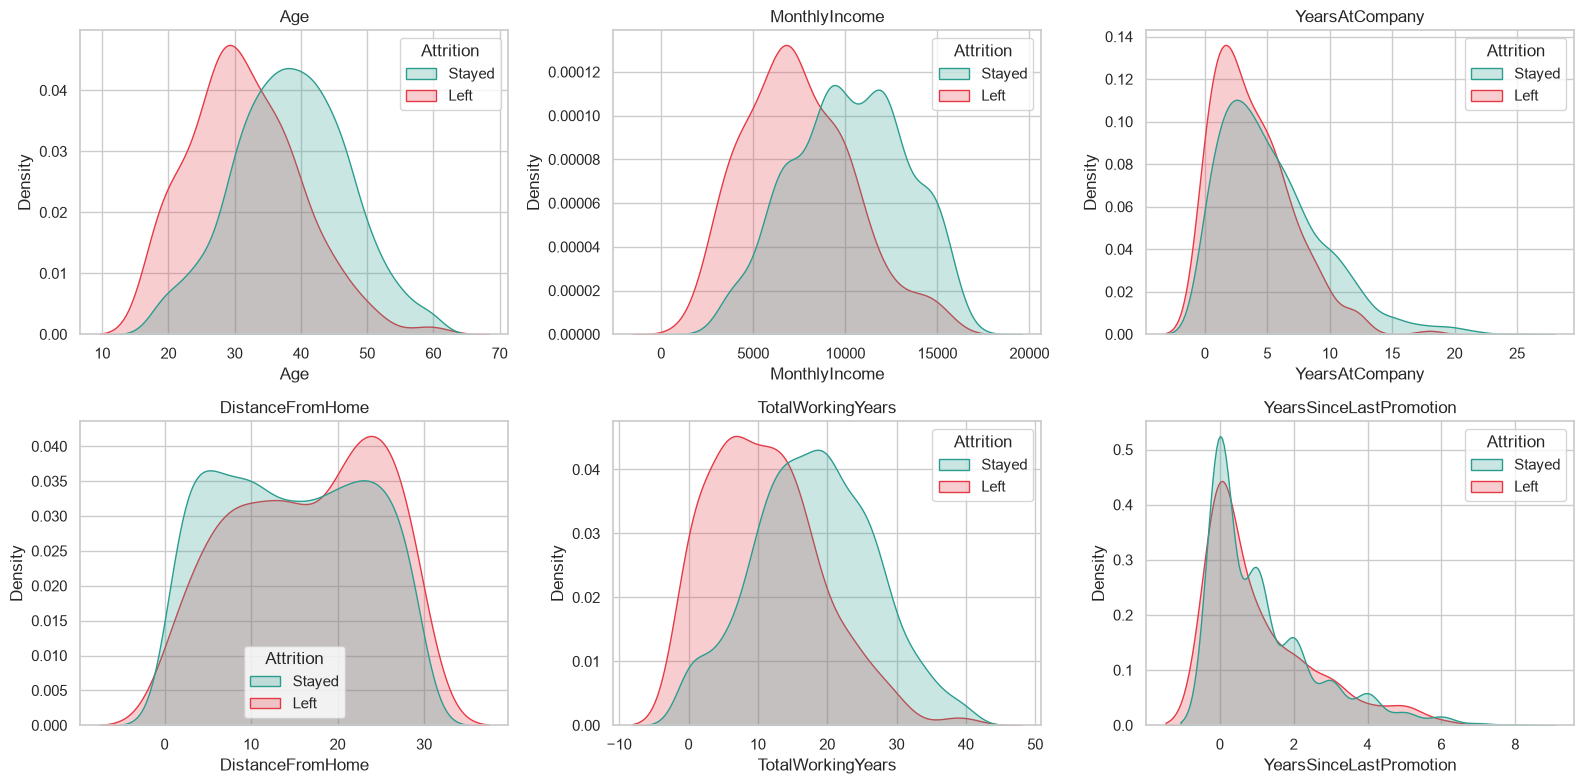

In [37]:
num_eda = ["Age", "MonthlyIncome", "YearsAtCompany", "DistanceFromHome",
           "TotalWorkingYears", "YearsSinceLastPromotion"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), num_eda):
    sns.kdeplot(data=df, x=col, hue=df["Attrition"].map({0: "Stayed", 1: "Left"}), fill=True,
                common_norm=False, palette={"Stayed": "#2a9d8f", "Left": "#e63946"}, ax=ax)
    ax.set_title(col)
save_fig("03_numeric_distributions"); plt.show()

### 5.5 Retention analysis: when do employees leave?

This is the **workforce retention** part of the project: how attrition changes with tenure, pay and time since last promotion.

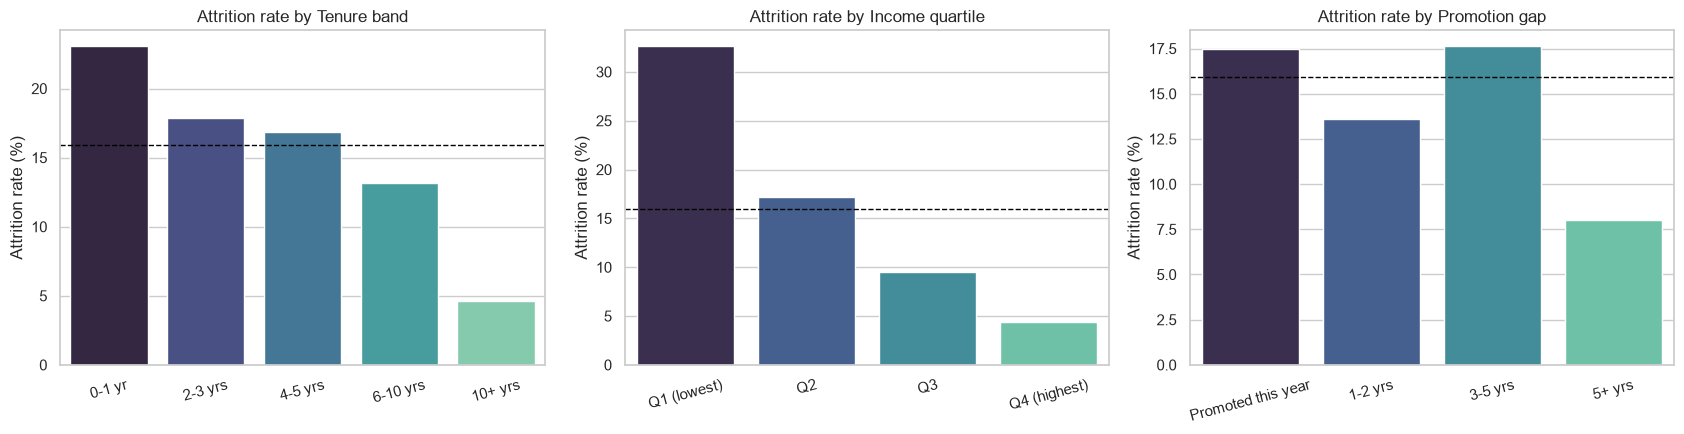

Highest-attrition tenure band in this data: 0-1 yr


In [38]:
tmp = df.copy()
tmp["Tenure band"] = pd.cut(tmp["YearsAtCompany"], [-1, 1, 3, 5, 10, 50],
                            labels=["0-1 yr", "2-3 yrs", "4-5 yrs", "6-10 yrs", "10+ yrs"])
tmp["Income quartile"] = pd.qcut(tmp["MonthlyIncome"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
tmp["Promotion gap"] = pd.cut(tmp["YearsSinceLastPromotion"], [-1, 0, 2, 5, 50],
                              labels=["Promoted this year", "1-2 yrs", "3-5 yrs", "5+ yrs"])

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, ["Tenure band", "Income quartile", "Promotion gap"]):
    r = tmp.groupby(col, observed=True)["Attrition"].mean() * 100
    sns.barplot(x=r.index.astype(str), y=r.values, palette="mako", ax=ax)
    ax.axhline(rate * 100, color="black", ls="--", lw=1)
    ax.set_title(f"Attrition rate by {col}"); ax.set_ylabel("Attrition rate (%)"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
save_fig("04_retention_analysis"); plt.show()

hi = tmp.groupby("Tenure band", observed=True)["Attrition"].mean().idxmax()
print(f"Highest-attrition tenure band in this data: {hi}")

### 5.6 Correlation analysis

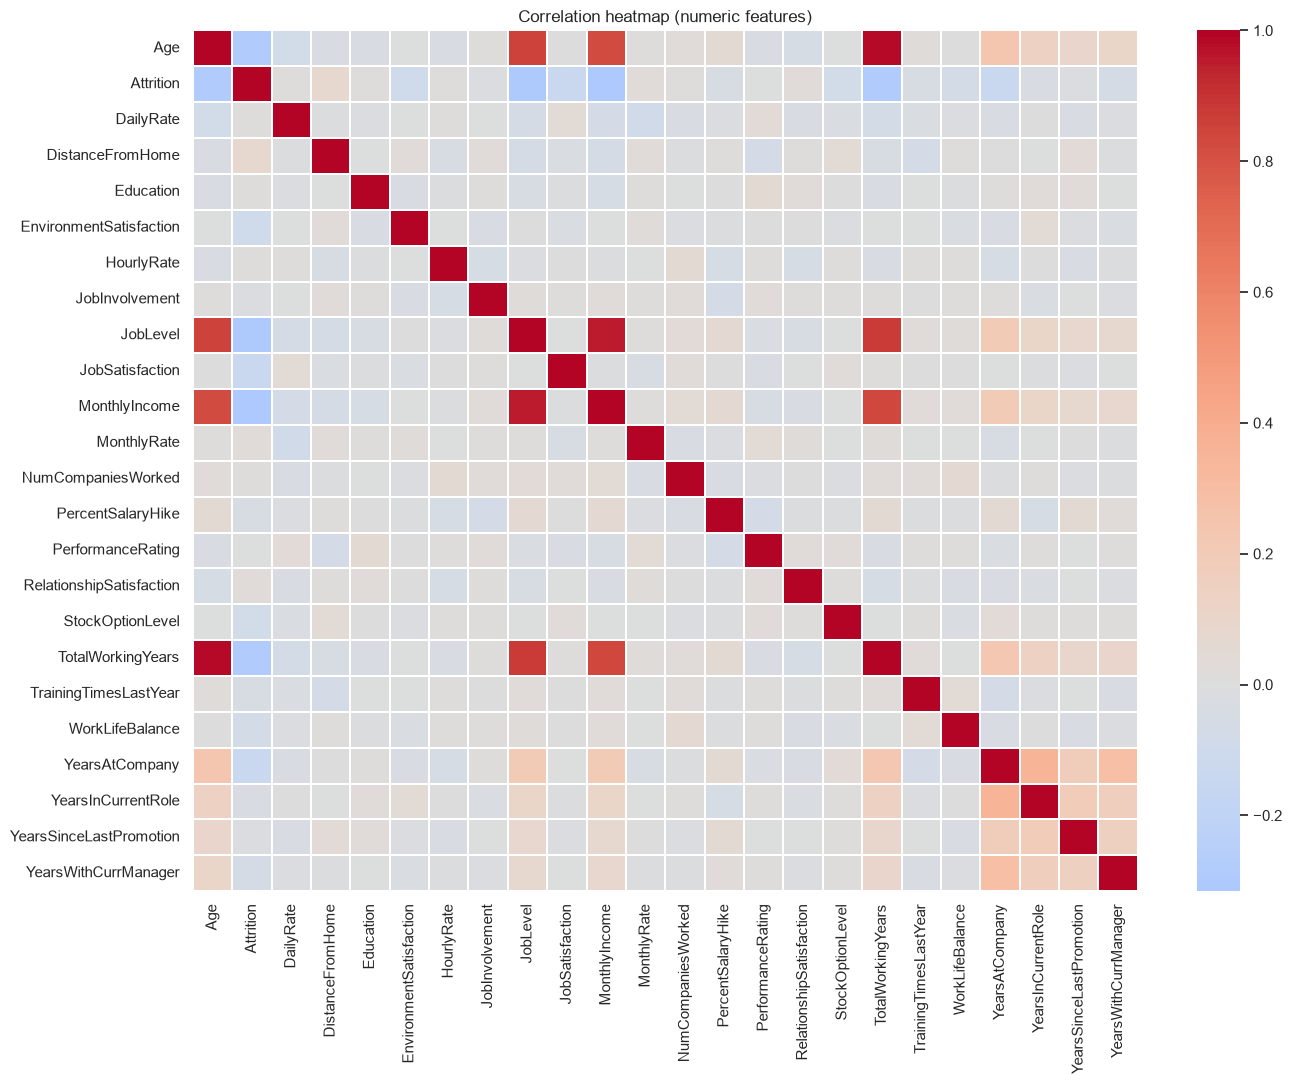

Strongest negative correlations with attrition:
 MonthlyIncome       -0.316
JobLevel            -0.309
TotalWorkingYears   -0.293
Age                 -0.289
YearsAtCompany      -0.139
Name: Attrition, dtype: float64

Strongest positive correlations with attrition:
 NumCompaniesWorked          0.015
Education                   0.017
RelationshipSatisfaction    0.024
MonthlyRate                 0.033
DistanceFromHome            0.079
Name: Attrition, dtype: float64


In [39]:
num_df = df.select_dtypes(include=np.number)
plt.figure(figsize=(14, 11))
sns.heatmap(num_df.corr(), cmap="coolwarm", center=0, annot=False, linewidths=0.2)
plt.title("Correlation heatmap (numeric features)")
save_fig("05_correlation_heatmap"); plt.show()

tc = num_df.corr()["Attrition"].drop("Attrition").sort_values()
print("Strongest negative correlations with attrition:\n", tc.head(5).round(3))
print("\nStrongest positive correlations with attrition:\n", tc.tail(5).round(3))

Several tenure features (`YearsAtCompany`, `YearsInCurrentRole`, `YearsWithCurrManager`, `TotalWorkingYears`) and `JobLevel` / `MonthlyIncome` are strongly correlated with each other. This **multicollinearity** is one reason we also use feature selection and tree-based models.

## 6. Feature Engineering and Selection

### 6.1 Feature engineering (HR-meaningful ratios) and excluding sensitive attributes
We add five HR-meaningful features. We also **exclude `Gender` and `MaritalStatus` from the model inputs**: using them to rate employees would be ethically and legally questionable. They remain available only for the fairness audit. (`Age` is kept because it is closely tied to experience, and it is also audited.)

In [40]:
def add_features(d):
    d = d.copy()
    d["SatisfactionIndex"] = d[["EnvironmentSatisfaction", "JobSatisfaction",
                                "RelationshipSatisfaction", "WorkLifeBalance"]].mean(axis=1)
    d["IncomePerExperienceYear"] = d["MonthlyIncome"] / (d["TotalWorkingYears"] + 1)
    d["TenureRatio"] = d["YearsAtCompany"] / (d["TotalWorkingYears"] + 1)           # loyalty to this employer
    d["AvgYearsPerCompany"] = d["TotalWorkingYears"] / (d["NumCompaniesWorked"] + 1) # job-hopping indicator
    d["PromotionStagnation"] = d["YearsSinceLastPromotion"] / (d["YearsAtCompany"] + 1)
    return d

X_all = add_features(df.drop(columns="Attrition"))
y_all = df["Attrition"]

# Fairness by design: sensitive attributes are NOT used as model inputs.
# They are kept aside and used only to audit the model for bias (section 12.6).
SENSITIVE = ["Gender", "MaritalStatus"]
sensitive_df = X_all[SENSITIVE].copy()
X_all = X_all.drop(columns=SENSITIVE)
print("Model input features after engineering:", X_all.shape[1], "| excluded sensitive:", SENSITIVE)
X_all.head(3)

Model input features after engineering: 33 | excluded sensitive: ['Gender', 'MaritalStatus']


,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,HourlyRate,JobInvolvement,...,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,SatisfactionIndex,IncomePerExperienceYear,TenureRatio,AvgYearsPerCompany,PromotionStagnation
0,30,Travel_Rarely,244,Sales,2,3,Other,4,64,4,...,1,3,3,0,2,2.25,927.75,0.375000,1.4,0.000000
1,43,Non-Travel,595,Research & Development,11,4,Life Sciences,4,53,2,...,1,2,0,1,1,2.00,401.00,0.095238,20.0,0.333333
2,30,Travel_Rarely,388,Sales,3,5,Life Sciences,4,86,3,...,4,3,3,3,3,3.50,488.00,0.375000,3.5,0.750000


### 6.2 Train / test split and preprocessing

80% of employees are used for training and 20% are held back for the final test. Scaling and one-hot encoding live **inside the pipeline**, so they are learned from training data only (no data leakage).

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"Attrition in train: {y_train.mean():.1%} | in test: {y_test.mean():.1%}")

cat_cols = X_all.select_dtypes(include="object").columns.tolist()
num_cols = [c for c in X_all.columns if c not in cat_cols]
print("\nCategorical:", cat_cols)
print("Numeric    :", num_cols)

def build_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)],
        sparse_threshold=0)

Train: (1176, 33) | Test: (294, 33)
Attrition in train: 15.9% | in test: 16.0%

Categorical: ['BusinessTravel', 'Department', 'EducationField', 'JobRole', 'OverTime']
Numeric    : ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'SatisfactionIndex', 'IncomePerExperienceYear', 'TenureRatio', 'AvgYearsPerCompany', 'PromotionStagnation']


### 6.3 Feature selection

We rank features with **mutual information** (it captures non-linear relationships). Later, the number of features kept (`SelectKBest`) is treated as a **hyperparameter** and chosen by cross-validation.

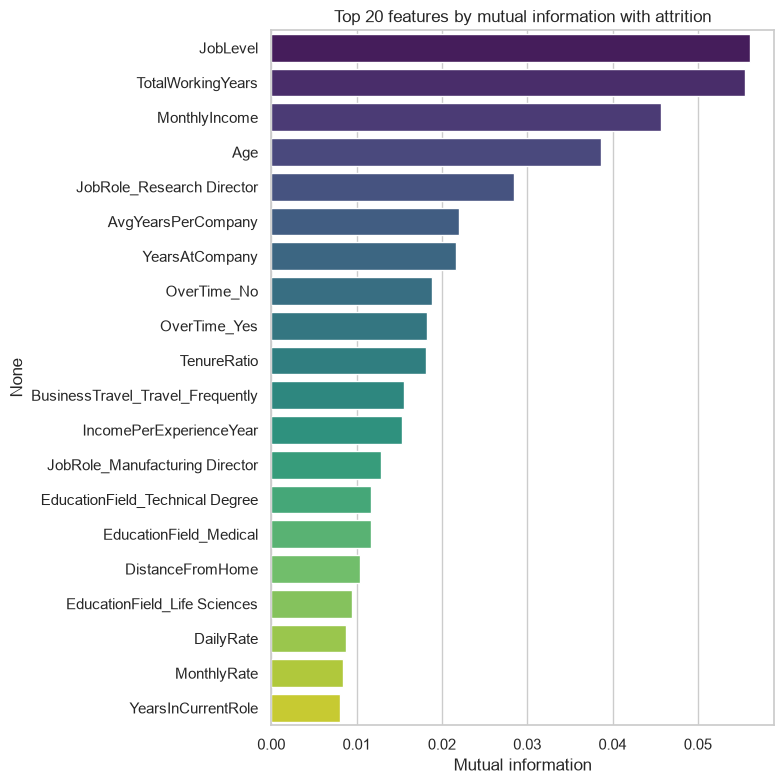

Total features after encoding: 51


In [42]:
prep_tmp = build_preprocessor().fit(X_train)
Xt = prep_tmp.transform(X_train)
names = [n.replace("num__", "").replace("cat__", "") for n in prep_tmp.get_feature_names_out()]
mi = pd.Series(mutual_info_classif(Xt, y_train, random_state=RANDOM_STATE), index=names).sort_values(ascending=False)

plt.figure(figsize=(8, 8))
sns.barplot(x=mi.head(20).values, y=mi.head(20).index, palette="viridis")
plt.title("Top 20 features by mutual information with attrition"); plt.xlabel("Mutual information")
save_fig("06_mutual_information"); plt.show()
print(f"Total features after encoding: {len(names)}")

## 7. Selection and Implementation of ML Models

| Model | Why it is included |
|---|---|
| Logistic Regression | Simple, fast and **interpretable** (HR can read the coefficients) |
| Decision Tree | Easy-to-explain rules |
| Random Forest | Robust ensemble that handles non-linear patterns |
| Gradient Boosting (HistGradientBoosting) | Usually the strongest on tabular data |
| SVM (RBF) | Strong on small datasets with scaled features |

**Class imbalance** is handled with `class_weight="balanced"`, which makes mistakes on the minority class (employees who leave) count more.

In [43]:
def make_pipe(model, k="all"):
    return Pipeline([("prep", build_preprocessor()),
                     ("select", SelectKBest(f_classif, k=k)),
                     ("model", model)])

base_models = {
    "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, class_weight="balanced",
                                            random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
                                            random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(learning_rate=0.05, max_depth=3, max_iter=200,
                                                        class_weight="balanced", random_state=RANDOM_STATE),
    "SVM (RBF)": SVC(probability=True, class_weight="balanced", random_state=RANDOM_STATE),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 8. Model Training and Testing

### 8.1 Baseline comparison with 5-fold stratified cross-validation (training data only)

In [44]:
scoring = {"ROC-AUC": "roc_auc", "PR-AUC": "average_precision", "Recall": "recall",
           "Precision": "precision", "F1": "f1"}
rows = []
for name, model in base_models.items():
    res = cross_validate(make_pipe(model), X_train, y_train, cv=cv, scoring=scoring)
    rows.append({"Model": name, **{m: res[f"test_{m}"].mean() for m in scoring}})
baseline_cv = pd.DataFrame(rows).set_index("Model").round(3)
baseline_cv.sort_values("PR-AUC", ascending=False)

,ROC-AUC,PR-AUC,Recall,Precision,F1
Model,,,,,
Logistic Regression,0.797,0.473,0.711,0.352,0.470
Random Forest,0.776,0.451,0.294,0.609,0.389
Gradient Boosting,0.755,0.427,0.524,0.378,0.439
SVM (RBF),0.763,0.405,0.567,0.380,0.453
Decision Tree,0.695,0.330,0.625,0.289,0.394


A random classifier would have a PR-AUC equal to the attrition rate (about 0.16), so anything clearly above that is real signal.

### 8.2 Hyperparameter tuning (including the number of selected features)

In [45]:
grids = {
    "Logistic Regression": (base_models["Logistic Regression"],
        {"select__k": [15, 25, "all"], "model__C": [0.05, 0.1, 0.5, 1, 5]}),
    "Random Forest": (RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                                             random_state=RANDOM_STATE, n_jobs=-1),
        {"select__k": [15, 25, "all"], "model__max_depth": [4, 8, None], "model__min_samples_leaf": [2, 5, 10]}),
    "Gradient Boosting": (base_models["Gradient Boosting"],
        {"select__k": [15, "all"], "model__max_depth": [2, 3], "model__learning_rate": [0.03, 0.08]}),
}
tuned = {}
for name, (model, grid) in grids.items():
    gs = GridSearchCV(make_pipe(model), grid, cv=cv, scoring="average_precision", n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[name] = gs
    print(f"{name:<20} best CV PR-AUC = {gs.best_score_:.3f}   params = {gs.best_params_}")

Logistic Regression  best CV PR-AUC = 0.499   params = {'model__C': 0.1, 'select__k': 15}
Random Forest        best CV PR-AUC = 0.464   params = {'model__max_depth': 8, 'model__min_samples_leaf': 5, 'select__k': 'all'}
Gradient Boosting    best CV PR-AUC = 0.468   params = {'model__learning_rate': 0.03, 'model__max_depth': 2, 'select__k': 15}


## 9. Model Selection (without touching the test set)

In [46]:
candidates = {f"{n} (tuned)": g.best_estimator_ for n, g in tuned.items()}
candidates["Decision Tree"] = make_pipe(base_models["Decision Tree"])
candidates["SVM (RBF)"] = make_pipe(base_models["SVM (RBF)"])

rows = []
for name, est in candidates.items():
    res = cross_validate(est, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({"Model": name, **{m: res[f"test_{m}"].mean() for m in scoring}})
selection = pd.DataFrame(rows).set_index("Model").round(3).sort_values("PR-AUC", ascending=False)
display(selection)

best_name = selection.index[0]
# Class weights make raw scores over-confident, so we calibrate them into realistic probabilities.
best_model = CalibratedClassifierCV(candidates[best_name], method="sigmoid", cv=5).fit(X_train, y_train)
print("\nSelected final model:", best_name, "(with probability calibration)")

,ROC-AUC,PR-AUC,Recall,Precision,F1
Model,,,,,
Logistic Regression (tuned),0.805,0.499,0.738,0.348,0.473
Gradient Boosting (tuned),0.776,0.468,0.690,0.347,0.460
Random Forest (tuned),0.779,0.464,0.438,0.429,0.433
SVM (RBF),0.763,0.405,0.567,0.380,0.453
Decision Tree,0.695,0.330,0.625,0.289,0.394



Selected final model: Logistic Regression (tuned) (with probability calibration)


**Selection rule:** the final model is chosen by **cross-validated PR-AUC on the training data**. The test set is *not* used to choose the model or the threshold. It is used once, at the end, to report honest performance.

Because we used class weights, the raw scores overstate the chance of leaving. We therefore **calibrate** the chosen model (sigmoid / Platt scaling, fitted on training data only), so that a score of 0.30 really means "about 30% of such employees leave". This matters because the business decision below relies on real probabilities.

## 10. Choosing the Decision Threshold with a Business Cost-Benefit Rule

The model outputs a **probability of leaving**. Turning that into "flag this employee for a retention conversation" needs a threshold, and 0.5 is rarely right. We choose it using costs.

**Business assumptions (editable; replace them with your organisation's figures):**
- Replacing an employee who leaves costs **6 months of their salary** (recruiting, onboarding, lost productivity).
- A retention action (stay interview, raise, role change, flexibility) costs about **5% of annual salary** per flagged employee.
- A retention action successfully keeps **30%** of the employees who would have left.

For each flagged employee: if they would have left, the expected gain is `success_rate x replacement_cost - action_cost`; if they would have stayed, we lose the `action_cost`. We pick the threshold that maximises total net benefit on **out-of-fold training predictions**.

*Sanity check from theory:* flagging an employee pays off when `probability x success_rate x replacement_cost > action_cost`, i.e. when the probability exceeds `action_cost / (success_rate x replacement_cost)`. With the assumptions above that break-even point is about **0.33**, and the data-driven threshold should land in that neighbourhood.

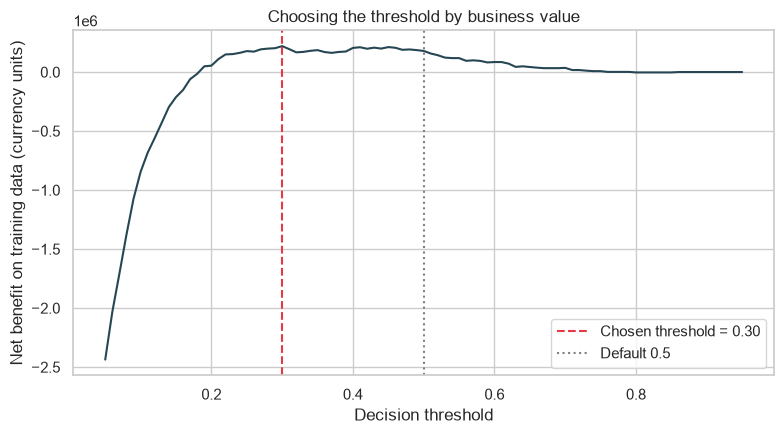

Chosen threshold: 0.30
Theoretical break-even probability from the cost assumptions: 0.33


In [47]:
REPLACEMENT_MONTHS = 6          # cost of replacing a leaver, in months of salary
ACTION_COST_PCT    = 0.05       # retention action cost, as a fraction of annual salary
SUCCESS_RATE       = 0.30       # share of would-be leavers the action keeps

def net_benefit(y_true, flagged, monthly_income):
    y_true, flagged = np.asarray(y_true), np.asarray(flagged).astype(bool)
    income = np.asarray(monthly_income, dtype=float)
    replacement = REPLACEMENT_MONTHS * income
    action = ACTION_COST_PCT * 12 * income
    gain = np.where(y_true == 1, SUCCESS_RATE * replacement - action, -action)
    return float(gain[flagged].sum())

oof = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
grid = np.linspace(0.05, 0.95, 91)
benefits = [net_benefit(y_train, oof >= t, X_train["MonthlyIncome"]) for t in grid]
THRESHOLD = float(grid[int(np.argmax(benefits))])

plt.figure(figsize=(8, 4.5))
plt.plot(grid, benefits, color="#264653")
plt.axvline(THRESHOLD, color="#e63946", ls="--", label=f"Chosen threshold = {THRESHOLD:.2f}")
plt.axvline(0.5, color="grey", ls=":", label="Default 0.5")
plt.xlabel("Decision threshold"); plt.ylabel("Net benefit on training data (currency units)")
plt.title("Choosing the threshold by business value"); plt.legend()
save_fig("07_threshold_selection"); plt.show()
breakeven = ACTION_COST_PCT * 12 / (SUCCESS_RATE * REPLACEMENT_MONTHS)
print(f"Chosen threshold: {THRESHOLD:.2f}")
print(f"Theoretical break-even probability from the cost assumptions: {breakeven:.2f}")

## 11. Performance Evaluation (on the unseen test set)

In [48]:
proba_test = best_model.predict_proba(X_test)[:, 1]

def metrics_at(th):
    pred = (proba_test >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"Threshold": round(th, 2), "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
            "Leavers caught (TP)": tp, "Leavers missed (FN)": fn, "False alarms (FP)": fp}

print(f"Threshold-independent metrics ->  ROC-AUC: {roc_auc_score(y_test, proba_test):.3f}   "
      f"PR-AUC: {average_precision_score(y_test, proba_test):.3f}   (random PR-AUC = {y_test.mean():.3f})\n")
pd.DataFrame([metrics_at(0.5), metrics_at(THRESHOLD)], index=["Default 0.5", "Business threshold"]).round(3)

Threshold-independent metrics ->  ROC-AUC: 0.828   PR-AUC: 0.481   (random PR-AUC = 0.160)



,Threshold,Accuracy,Precision,Recall,F1,Leavers caught (TP),Leavers missed (FN),False alarms (FP)
Default 0.5,0.5,0.847,0.55,0.234,0.328,11,36,9
Business threshold,0.3,0.840,0.50,0.532,0.515,25,22,25


In [49]:
pred_test = (proba_test >= THRESHOLD).astype(int)
print(classification_report(y_test, pred_test, target_names=["Stayed", "Left"], digits=3))

              precision    recall  f1-score   support

      Stayed      0.910     0.899     0.904       247
        Left      0.500     0.532     0.515        47

    accuracy                          0.840       294
   macro avg      0.705     0.715     0.710       294
weighted avg      0.844     0.840     0.842       294



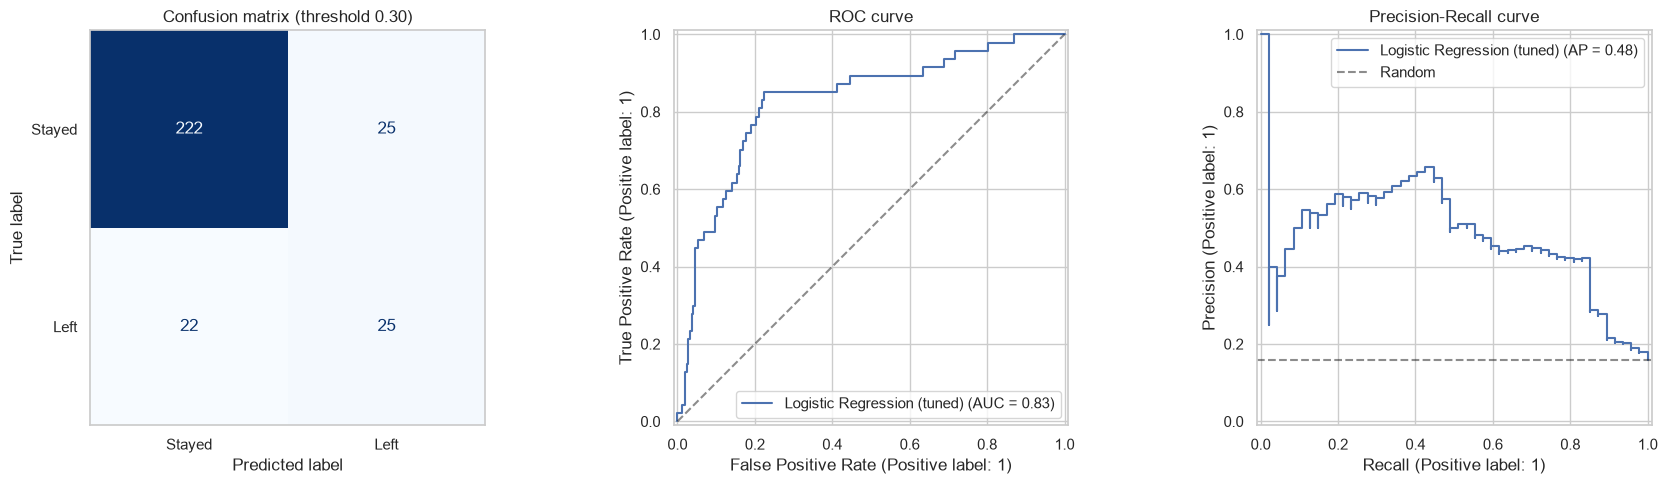

In [50]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["Stayed", "Left"],
                                        cmap="Blues", ax=ax[0], colorbar=False)
ax[0].set_title(f"Confusion matrix (threshold {THRESHOLD:.2f})"); ax[0].grid(False)
RocCurveDisplay.from_predictions(y_test, proba_test, ax=ax[1], name=best_name)
ax[1].plot([0, 1], [0, 1], "k--", alpha=.5); ax[1].set_title("ROC curve")
PrecisionRecallDisplay.from_predictions(y_test, proba_test, ax=ax[2], name=best_name)
ax[2].axhline(y_test.mean(), color="k", ls="--", alpha=.5, label="Random"); ax[2].legend()
ax[2].set_title("Precision-Recall curve")
save_fig("08_evaluation"); plt.show()

**Reading the results:** a *missed leaver* (false negative) costs the company a replacement, while a *false alarm* only costs a conversation, so recall is weighted heavily through the business threshold. With a small test set, treat the numbers as estimates with some uncertainty, not exact truths.

## 12. Results and Visualization

### 12.1 Why do employees leave? (model explanation)

We use two complementary views: **permutation importance** (how much performance drops when a feature is shuffled, for the final model) and **logistic regression odds ratios** (direction and size of each effect).

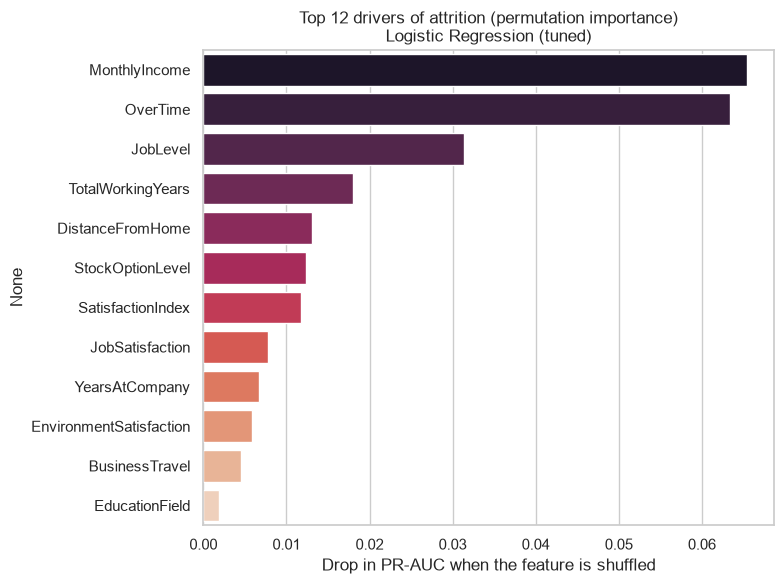

In [51]:
perm = permutation_importance(best_model, X_test, y_test, scoring="average_precision",
                              n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False).head(12)

plt.figure(figsize=(8, 6))
sns.barplot(x=imp.values, y=imp.index, palette="rocket")
plt.title(f"Top 12 drivers of attrition (permutation importance)\n{best_name}")
plt.xlabel("Drop in PR-AUC when the feature is shuffled")
save_fig("09_permutation_importance"); plt.show()

Explanation model (logistic regression) test ROC-AUC: 0.845


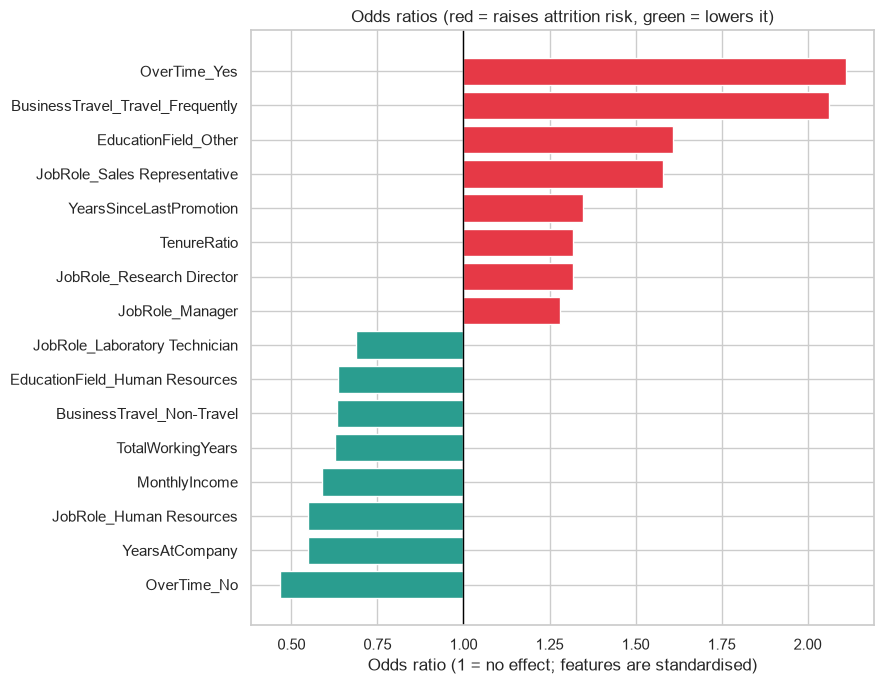

In [52]:
lr_explain = make_pipe(LogisticRegression(C=0.5, max_iter=3000, class_weight="balanced",
                                          random_state=RANDOM_STATE)).fit(X_train, y_train)
print(f"Explanation model (logistic regression) test ROC-AUC: "
      f"{roc_auc_score(y_test, lr_explain.predict_proba(X_test)[:, 1]):.3f}")

lr_names = [n.replace("num__", "").replace("cat__", "")
            for n in lr_explain.named_steps["prep"].get_feature_names_out()]
coef = pd.Series(lr_explain.named_steps["model"].coef_[0], index=lr_names)
odds = np.exp(coef).sort_values()
show = pd.concat([odds.head(8), odds.tail(8)])

plt.figure(figsize=(9, 7))
colors = ["#2a9d8f" if v < 1 else "#e63946" for v in show.values]
plt.barh(show.index, show.values - 1, left=1, color=colors)
plt.axvline(1, color="black", lw=1)
plt.title("Odds ratios (red = raises attrition risk, green = lowers it)")
plt.xlabel("Odds ratio (1 = no effect; features are standardised)")
save_fig("10_odds_ratios"); plt.show()

### 12.2 Risk score for every employee

To score all employees fairly, we use **cross-validated predictions** (each employee is scored by a model that did not see them during training).

,Employees,Avg_Risk,Actual_Attrition_Rate,Share_of_Workforce
Risk_Tier,,,,
Low,931,0.067,0.054,0.633
Medium,311,0.215,0.244,0.212
High,228,0.460,0.474,0.155


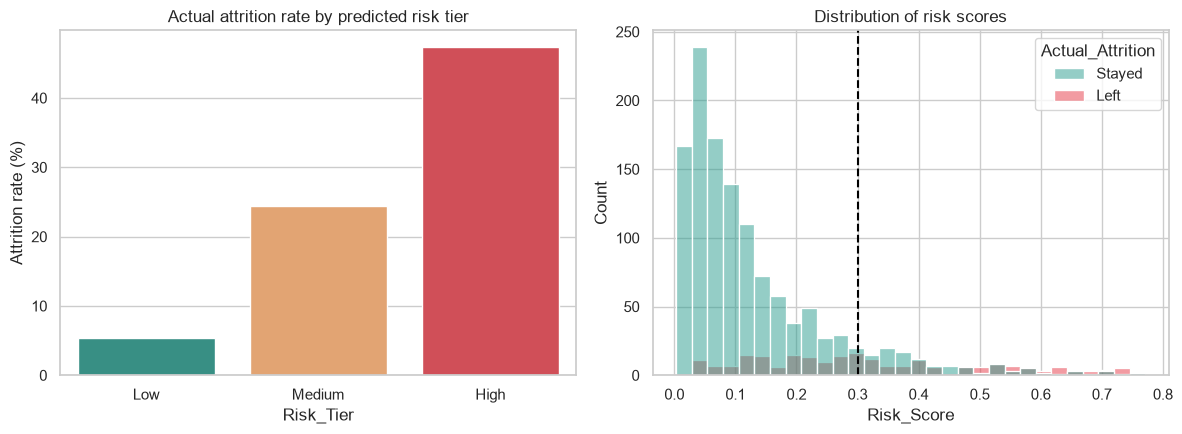

In [53]:
risk = cross_val_predict(best_model, X_all, y_all, cv=cv, method="predict_proba")[:, 1]
scored = X_all.copy()
scored.insert(0, "EmployeeNumber", employee_ids.values)
scored["Actual_Attrition"] = y_all.values
scored["Risk_Score"] = risk
scored["Risk_Tier"] = np.where(risk >= THRESHOLD, "High",
                        np.where(risk >= THRESHOLD / 2, "Medium", "Low"))

tier = scored.groupby("Risk_Tier").agg(Employees=("Risk_Score", "size"),
                                       Avg_Risk=("Risk_Score", "mean"),
                                       Actual_Attrition_Rate=("Actual_Attrition", "mean")).loc[["Low", "Medium", "High"]]
tier["Share_of_Workforce"] = tier["Employees"] / len(scored)
display(tier.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(x=tier.index, y=tier["Actual_Attrition_Rate"] * 100,
            palette=["#2a9d8f", "#f4a261", "#e63946"], ax=ax[0])
ax[0].set_title("Actual attrition rate by predicted risk tier"); ax[0].set_ylabel("Attrition rate (%)")
sns.histplot(data=scored, x="Risk_Score", hue=scored["Actual_Attrition"].map({0: "Stayed", 1: "Left"}),
             bins=30, palette={"Stayed": "#2a9d8f", "Left": "#e63946"}, ax=ax[1])
ax[1].axvline(THRESHOLD, color="black", ls="--"); ax[1].set_title("Distribution of risk scores")
save_fig("11_risk_tiers"); plt.show()

If the model works, the **actual** attrition rate should climb steeply from the Low to the High tier. This is a sanity check that the tiers are meaningful for HR.

### 12.3 Where is the risk concentrated? (departments and roles)

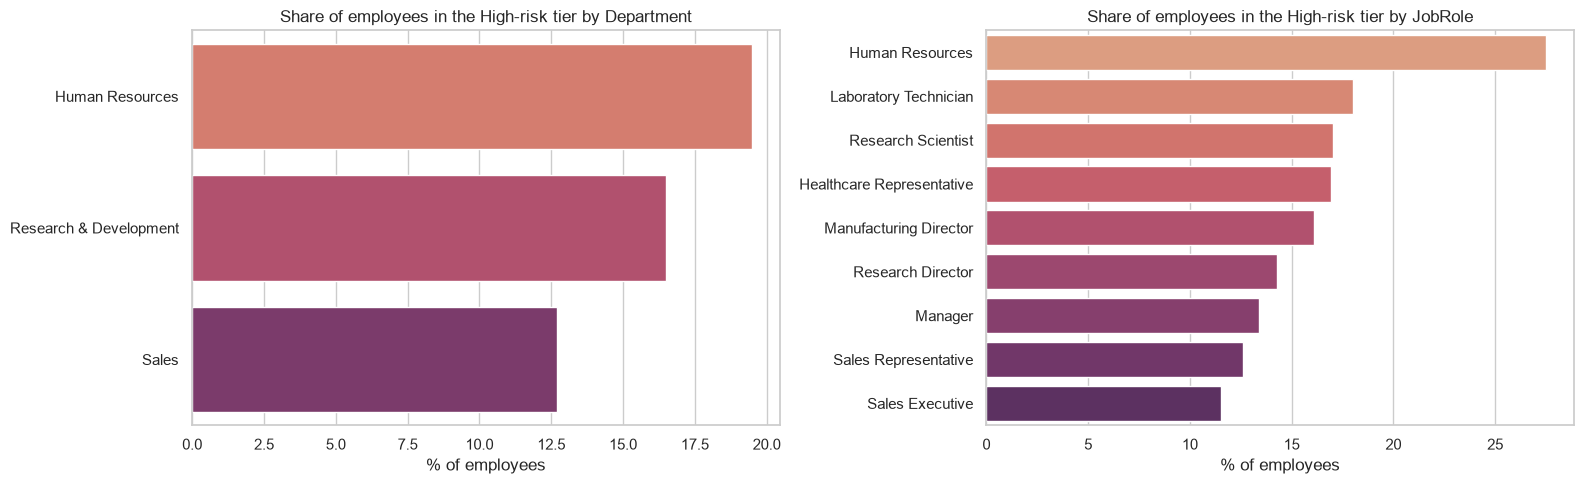

In [54]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
for a, col in zip(ax, ["Department", "JobRole"]):
    g = scored.groupby(col).agg(Avg_Risk=("Risk_Score", "mean"), High_Risk=("Risk_Tier", lambda s: (s == "High").mean()))
    g = g.sort_values("High_Risk", ascending=False)
    sns.barplot(x=g["High_Risk"] * 100, y=g.index, palette="flare", ax=a)
    a.set_title(f"Share of employees in the High-risk tier by {col}"); a.set_xlabel("% of employees"); a.set_ylabel("")
save_fig("12_risk_by_group"); plt.show()

### 12.4 Who should HR talk to first? (top at-risk employees with reasons)

In [55]:
prep_lr = lr_explain.named_steps["prep"]
lr_coef = lr_explain.named_steps["model"].coef_[0]

def top_drivers(rows, n=3):
    '''For each employee: the n features that push their risk up the most (from the logistic model).'''
    contrib = prep_lr.transform(rows) * lr_coef
    out = []
    for c in contrib:
        idx = np.argsort(c)[::-1][:n]
        out.append(", ".join(lr_names[i] for i in idx if c[i] > 0))
    return out

watchlist = scored[scored["Risk_Tier"] == "High"].sort_values("Risk_Score", ascending=False).copy()
watchlist["Top_Risk_Drivers"] = top_drivers(X_all.loc[watchlist.index])
cols = ["EmployeeNumber", "Department", "JobRole", "MonthlyIncome", "Risk_Score", "Actual_Attrition", "Top_Risk_Drivers"]
watchlist[cols].to_csv("reports/high_risk_employees.csv", index=False)
print(f"{len(watchlist)} employees in the High-risk tier. Saved to reports/high_risk_employees.csv")
watchlist[cols].head(10).round(3)

228 employees in the High-risk tier. Saved to reports/high_risk_employees.csv


,EmployeeNumber,Department,JobRole,MonthlyIncome,Risk_Score,Actual_Attrition,Top_Risk_Drivers
1028,1029,Sales,Sales Representative,6083,0.771,0,"TotalWorkingYears, OverTime_Yes, MonthlyIncome"
924,925,Research & Development,Healthcare Representative,4611,0.753,1,"MonthlyIncome, OverTime_Yes, SatisfactionIndex"
1367,1368,Research & Development,Healthcare Representative,5218,0.750,0,"MonthlyIncome, OverTime_Yes, BusinessTravel_Tr..."
1084,1085,Human Resources,Human Resources,3694,0.733,1,"MonthlyIncome, OverTime_Yes, BusinessTravel_Tr..."
574,575,Sales,Sales Executive,4585,0.732,1,"MonthlyIncome, OverTime_Yes, BusinessTravel_Tr..."
778,779,Sales,Manager,5416,0.730,1,"TotalWorkingYears, YearsAtCompany, OverTime_Yes"
1346,1347,Research & Development,Healthcare Representative,3876,0.729,0,"MonthlyIncome, OverTime_Yes, TotalWorkingYears"
849,850,Human Resources,Human Resources,8162,0.726,1,"TotalWorkingYears, YearsAtCompany, OverTime_Yes"
803,804,Research & Development,Manufacturing Director,3553,0.721,1,"MonthlyIncome, OverTime_Yes, BusinessTravel_Tr..."
532,533,Research & Development,Healthcare Representative,4454,0.715,0,"TotalWorkingYears, MonthlyIncome, YearsAtCompany"


### 12.5 Employee segments (clustering)

Besides predicting individuals, HR also wants to know *what kinds of employees* the company has. We cluster employees with **K-Means** on key workforce features and choose between 3 and 6 clusters with the silhouette score (at least 3, so the profiles are detailed enough to act on).

Silhouette by k: {3: 0.186, 4: 0.145, 5: 0.148, 6: 0.142} -> using k = 3


,Employees,Age,MonthlyIncome,TotalWorkingYears,YearsAtCompany,YearsSinceLastPromotion,DistanceFromHome,SatisfactionIndex,NumCompaniesWorked,Risk_Score,Actual_Attrition
Segment,,,,,,,,,,,
0,611,29.34,6938.88,8.82,3.88,0.76,15.60,2.70,2.47,0.26,0.28
1,575,44.39,12204.16,24.12,4.02,0.69,13.98,2.72,2.58,0.08,0.07
2,284,40.31,10972.99,19.89,9.93,2.83,15.68,2.68,2.58,0.08,0.08


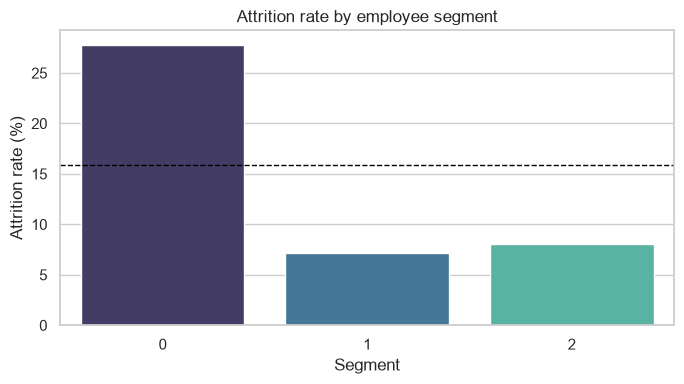

In [56]:
seg_cols = ["Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany", "YearsSinceLastPromotion",
            "DistanceFromHome", "SatisfactionIndex", "NumCompaniesWorked"]
Z = StandardScaler().fit_transform(X_all[seg_cols])

sil = {k: silhouette_score(Z, KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(Z)) for k in range(3, 7)}
best_k = max(sil, key=sil.get)
print("Silhouette by k:", {k: round(v, 3) for k, v in sil.items()}, "-> using k =", best_k)

scored["Segment"] = KMeans(best_k, n_init=10, random_state=RANDOM_STATE).fit_predict(Z)
profile = scored.groupby("Segment")[seg_cols + ["Risk_Score", "Actual_Attrition"]].mean()
profile.insert(0, "Employees", scored["Segment"].value_counts().sort_index())
display(profile.round(2))

plt.figure(figsize=(7, 4))
r = scored.groupby("Segment")["Actual_Attrition"].mean() * 100
sns.barplot(x=r.index, y=r.values, palette="mako")
plt.axhline(rate * 100, color="black", ls="--", lw=1)
plt.title("Attrition rate by employee segment"); plt.ylabel("Attrition rate (%)")
save_fig("13_segments"); plt.show()

Read the profile table to name each segment yourself (for example *young, recently joined, low pay* versus *experienced, long tenure, well paid*), and look at which segment has the highest attrition. These names should come from the numbers you see.

### 12.6 Fairness check

A model used on people must not systematically treat groups differently. We compare how often the model **flags** employees and how many real leavers it **catches** across groups on the test set. Large gaps would need investigation before any real use.

In [57]:
check = X_test.join(sensitive_df.loc[X_test.index])
check["Pred"] = pred_test
check["Actual"] = y_test.values
check["AgeGroup"] = pd.cut(check["Age"], [0, 29, 45, 100], labels=["<30", "30-45", "46+"])

rows = []
for col in ["Gender", "MaritalStatus", "AgeGroup"]:
    for grp, g in check.groupby(col, observed=True):
        leavers = g[g["Actual"] == 1]
        rows.append({"Attribute": col, "Group": grp, "Employees": len(g),
                     "Flag rate": g["Pred"].mean(),
                     "Recall (leavers caught)": leavers["Pred"].mean() if len(leavers) else np.nan,
                     "Actual leavers": len(leavers)})
display(pd.DataFrame(rows).round(3))

,Attribute,Group,Employees,Flag rate,Recall (leavers caught),Actual leavers
0,Gender,Female,126,0.183,0.526,19
1,Gender,Male,168,0.161,0.536,28
2,MaritalStatus,Divorced,75,0.213,0.750,12
3,MaritalStatus,Married,130,0.169,0.571,14
4,MaritalStatus,Single,89,0.135,0.381,21
5,AgeGroup,<30,54,0.519,0.762,21
6,AgeGroup,30-45,184,0.120,0.375,24
7,AgeGroup,46+,56,0.000,0.000,2


Groups with very few actual leavers give noisy recall values, so look at the *Flag rate* and the number of leavers together. Differences in flag rate can be legitimate (groups can genuinely differ in attrition) but should always be reviewed.

## 13. Business Impact and Retention Recommendations

### 13.1 What is the model worth? (test set)

In [58]:
income_test = X_test["MonthlyIncome"]
n = len(y_test)
strategies = {
    "Do nothing": np.zeros(n, dtype=bool),
    "Talk to everyone": np.ones(n, dtype=bool),
    "Use the model (business threshold)": pred_test.astype(bool),
}
res = pd.DataFrame({
    "Employees contacted": {k: int(v.sum()) for k, v in strategies.items()},
    "Net benefit": {k: net_benefit(y_test, v, income_test) for k, v in strategies.items()}})
display(res.round(0))

print("Assumptions: replacement cost =", REPLACEMENT_MONTHS, "months' salary; action cost =",
      f"{ACTION_COST_PCT:.0%} of annual salary; success rate = {SUCCESS_RATE:.0%}.")
print("These are illustrative assumptions. The ranking of strategies matters more than the absolute amount.")

,Employees contacted,Net benefit
Do nothing,0,0.0
Talk to everyone,294,-1105364.0
Use the model (business threshold),50,68968.0


Assumptions: replacement cost = 6 months' salary; action cost = 5% of annual salary; success rate = 30%.
These are illustrative assumptions. The ranking of strategies matters more than the absolute amount.


### 13.2 Suggested retention actions
The table links the main attrition drivers to practical HR actions. Treat these as **hypotheses to test** (for example with pilot programmes), because a model shows association, not proof of cause.

| If the model highlights... | Possible retention action |
|---|---|
| **OverTime** | Rebalance workloads, hire support staff, cap consecutive overtime, offer time off in lieu |
| **Low satisfaction / poor work-life balance** | Stay interviews, flexible hours or hybrid options, manager coaching |
| **Low income vs peers / low salary hike** | Market-based pay review, targeted raises for high performers |
| **Long gap since last promotion** | Clear career paths, regular promotion reviews, new responsibilities |
| **Short tenure (first 1-2 years)** | Stronger onboarding, mentoring, 30/60/90-day check-ins |
| **Frequent business travel / long commute** | Cap travel, remote days, commute or relocation support |
| **No stock options / low engagement** | Share-based incentives, recognition programmes |
| **Job-hopping history** | Early engagement and growth opportunities, realistic role previews |

## 14. Save the Model and Predict for a New Employee

In [59]:
joblib.dump({"model": best_model, "threshold": THRESHOLD, "columns": list(X_all.columns)},
            "models/attrition_model.joblib")
print("Saved models/attrition_model.joblib")

def predict_employee(employee: dict):
    '''employee: dict with the original dataset columns (e.g. one row of the CSV without Attrition).'''
    bundle = joblib.load("models/attrition_model.joblib")
    row = add_features(pd.DataFrame([employee]))[bundle["columns"]]
    p = float(bundle["model"].predict_proba(row)[0, 1])
    tier = "High" if p >= bundle["threshold"] else ("Medium" if p >= bundle["threshold"] / 2 else "Low")
    return {"risk_probability": round(p, 3), "risk_tier": tier, "main_drivers": top_drivers(row)[0]}

# Demo with three employees from the test set
original_cols = df.drop(columns="Attrition").columns
for i in X_test.index[:3]:
    result = predict_employee(df.loc[i, original_cols].to_dict())
    print(f"Employee row {i}: {result}   | actually left: {bool(y_all.loc[i])}")

Saved models/attrition_model.joblib
Employee row 1387: {'risk_probability': 0.21, 'risk_tier': 'Medium', 'main_drivers': 'MonthlyIncome, SatisfactionIndex, JobSatisfaction'}   | actually left: False
Employee row 893: {'risk_probability': 0.033, 'risk_tier': 'Low', 'main_drivers': 'YearsAtCompany, JobRole_Healthcare Representative, MonthlyRate'}   | actually left: False
Employee row 454: {'risk_probability': 0.043, 'risk_tier': 'Low', 'main_drivers': 'TenureRatio, StockOptionLevel, EnvironmentSatisfaction'}   | actually left: False


## 15. Conclusion

In [60]:
m = metrics_at(THRESHOLD)
print(f"Data source          : {DATA_SOURCE}")
print(f"Final model          : {best_name}")
print(f"ROC-AUC / PR-AUC     : {roc_auc_score(y_test, proba_test):.3f} / {average_precision_score(y_test, proba_test):.3f}")
print(f"At threshold {THRESHOLD:.2f}     : recall {m['Recall']:.1%}, precision {m['Precision']:.1%}")
print(f"Leavers caught/missed: {m['Leavers caught (TP)']} / {m['Leavers missed (FN)']} (of {int(y_test.sum())} in the test set)")
print("Top 5 drivers        :", ", ".join(imp.index[:5]))

Data source          : SIMULATED sample data (real CSV not found)
Final model          : Logistic Regression (tuned)
ROC-AUC / PR-AUC     : 0.828 / 0.481
At threshold 0.30     : recall 53.2%, precision 50.0%
Leavers caught/missed: 25 / 22 (of 47 in the test set)
Top 5 drivers        : MonthlyIncome, OverTime, JobLevel, TotalWorkingYears, DistanceFromHome


**Summary**
- We built an end-to-end system covering EDA, feature engineering and selection, five models, tuning, a business-driven threshold, explanations, risk tiers, segmentation, a fairness check and a business-impact estimate.
- The model turns HR data into a **prioritised list of at-risk employees with reasons**, so retention effort goes where it matters most.
- Choosing the model and threshold using only training data keeps the reported test performance honest.

**Limitations**
- The IBM dataset is a public, fictional benchmark. Real company data would differ, and results will not transfer directly.
- The model shows **association, not causation**: acting on a driver (for example reducing overtime) should be piloted and measured.
- The business assumptions (replacement cost, action cost, success rate) are illustrative and must be replaced with real figures.
- Predictions must **support** HR conversations and never be used for punishment, hiring or firing decisions.

**Future work**
- Add survival analysis (time until an employee leaves), SHAP explanations, probability calibration, and monitoring for data drift.
- Wrap the model in a Streamlit dashboard for HR managers, and retrain it regularly with new exit data.